### Lab 7 Demo
**Student:** Zaki Daouk  
**Date:** 2026-10-18

Note: Before running the notebook, it maybe important to install the engine and path helper in the Python environment used by its kernel. From the `phys311` project root, run `python -m pip install -e .\labs\lab07` in the VS Code terminal. The plots are also saved under `labs/lab07/figures/`.

## Part A - Engine Architecture

The engine separates body state, force models, numerical integration, and world orchestration. `World` owns the bodies and forces, applies forces before each integration step, and records state snapshots for diagnostics and plotting.

```text
+--------------------+      owns       +--------------------+
|       World        |---------------->|       Body         |
| bodies, forces     |                 | m, r, v, force     |
| integrator, time   |                 | theta, omega       |
| history            |                 +--------------------+
+---------+----------+                            ^
          |                                       | adds force
          v                                       |
+--------------------+                   +--------+---------+
|    Integrator      |                   |       Force      |
| step(world, dt)    |                   | apply(world)     |
+---------+----------+                   +---+----------+---+
          | updates                          |          |
          v                                  v          v
+--------------------+                 +----------+ +----------+
|   EulerCromer      |                 | Gravity  | |  Spring  |
+--------------------+                 +----------+ +----------+

World records StateRecord snapshots of positions, kinetic and potential
energy, and linear and angular momentum for plotting and conservation checks.
```

## Part B - Validate Against Earlier Labs

These three cases reuse the parameter sets from Labs 1, 3, and 6. Each simulation advances only through `World.run`; the dotted/solid reference curves show the known analytical or small-angle results from the original labs. Energy variation is reported as a numerical conservation check.

- **Models:** projectile motion, a spring oscillator, and a physical pendulum.
- **Comparison:** simulated results are checked against the earlier labs' reference solutions.
- **Validation:** energy and momentum behavior are reviewed, including timestep-related error.

In [9]:
import matplotlib.pyplot as plt
import numpy as np

from project_paths import add_to_path, project_root

ENGINE_DIR = add_to_path(
    "lab07_engine",
    subdirs=("", "src", "labs/lab07", "lab07", "phys311/labs/lab07"),
)

from lab07_engine import (  # noqa: E402
    Body,
    EulerCromer,
    Gravity,
    PendulumGravity,
    Spring,
    World,
)

ROOT = project_root(start=ENGINE_DIR)
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)


### Case 1 - Projectile (Lab 1)

The reference lab launches a projectile at 30 m/s and 45 degrees with a 0.01 s step and no drag. The engine trajectory is compared with the analytic parabola. The external gravitational force changes momentum, while total mechanical energy should remain nearly constant.

In [10]:
# Lab 1 projectile: 30 m/s at 45 degrees, no drag.
g = 9.81
projectile_mass = 1.0
projectile_speed = 30.0
projectile_angle = np.deg2rad(45.0)
projectile_dt = 0.01
projectile_flight_time = 2 * projectile_speed * np.sin(projectile_angle) / g
projectile_steps = int(np.ceil(projectile_flight_time / projectile_dt))

projectile_world = World(EulerCromer())
projectile_body = Body(
    projectile_mass,
    [0.0, 0.0],
    [projectile_speed * np.cos(projectile_angle), projectile_speed * np.sin(projectile_angle)],
)
projectile_world.add_body(projectile_body)
projectile_world.add_force(Gravity(g))
projectile_world.run(projectile_steps, projectile_dt)
projectile_times = np.array([state.time for state in projectile_world.history])
projectile_positions = np.array([state.positions[0] for state in projectile_world.history])
projectile_energy = np.array([state.total_energy for state in projectile_world.history])
projectile_momentum = np.array([state.momentum for state in projectile_world.history])
projectile_range_exact = projectile_speed**2 * np.sin(2 * projectile_angle) / g
projectile_energy_variation = np.ptp(projectile_energy) / projectile_energy[0]
projectile_expected_delta_py = -projectile_mass * g * projectile_times[-1]
assert projectile_energy_variation < 0.01
assert abs(projectile_momentum[-1, 1] - projectile_momentum[0, 1] - projectile_expected_delta_py) < 1e-8

### Case 2 - Simple Harmonic Oscillator (Lab 3)

The reference lab uses k = 1 N/m, m = 1 kg, x(0) = 1 m, v(0) = 0, and dt = T/50 for ten periods. A spring anchored at the origin supplies the restoring force. We compare position, velocity/phase space, and the bounded energy error with the exact oscillator solution.

In [11]:
spring_k = 1.0
oscillator_mass = 1.0
oscillator_omega = np.sqrt(spring_k / oscillator_mass)
oscillator_period = 2 * np.pi / oscillator_omega
oscillator_dt = oscillator_period / 50
oscillator_steps = 500

oscillator_world = World(EulerCromer())
oscillator_body = Body(oscillator_mass, [1.0, 0.0], [0.0, 0.0])
oscillator_world.add_body(oscillator_body)
oscillator_world.add_force(Spring(spring_k))
oscillator_world.run(oscillator_steps, oscillator_dt)
oscillator_times = np.array([state.time for state in oscillator_world.history])
oscillator_positions = np.array([state.positions[0] for state in oscillator_world.history])
oscillator_energy = np.array([state.total_energy for state in oscillator_world.history])
oscillator_x = oscillator_positions[:, 0]
oscillator_vx = np.array([
    (state.momentum[0] / oscillator_mass) for state in oscillator_world.history
])
oscillator_exact_x = np.cos(oscillator_omega * oscillator_times)
oscillator_exact_v = -oscillator_omega * np.sin(oscillator_omega * oscillator_times)
oscillator_energy_variation = np.ptp(oscillator_energy) / oscillator_energy[0]
crossing_indices = np.flatnonzero((oscillator_x[:-1] < 0) & (oscillator_x[1:] >= 0))
crossing_fractions = -oscillator_x[crossing_indices] / (
    oscillator_x[crossing_indices + 1] - oscillator_x[crossing_indices]
)
crossing_times = oscillator_times[crossing_indices] + crossing_fractions * oscillator_dt
measured_period = float(np.mean(np.diff(crossing_times)))
assert oscillator_energy_variation < 0.15
assert abs(measured_period - oscillator_period) / oscillator_period < 0.02

### Case 3 - Physical Pendulum (Lab 6)

The reference lab models a uniform rod with m = 1 kg, L = 1 m, pivot inertia I = mL^2/3, center-of-mass distance d = L/2, theta(0) = 0.3 rad, and dt = 0.001 s. The engine applies the nonlinear gravitational torque. The small-angle curve is overlaid as the reference, and total rotational-plus-gravitational energy is checked.

In [12]:
rod_mass = 1.0
rod_length = 1.0
rod_com_distance = rod_length / 2
rod_inertia = rod_mass * rod_length**2 / 3
initial_angle = 0.3
pendulum_dt = 0.001
pendulum_steps = 12000
small_angle_frequency = np.sqrt(rod_mass * g * rod_com_distance / rod_inertia)

pendulum_world = World(EulerCromer())
pendulum_body = Body(rod_mass, [0.0, 0.0], [0.0, 0.0], I=rod_inertia)
pendulum_body.theta = initial_angle
pendulum_world.add_body(pendulum_body)
pendulum_world.add_force(
    PendulumGravity(pendulum_body, rod_mass, g, rod_com_distance)
)
pendulum_world.run(pendulum_steps, pendulum_dt)
pendulum_times = np.array([state.time for state in pendulum_world.history])
pendulum_angles = np.array([state.angles[0] for state in pendulum_world.history])
pendulum_energy = np.array([state.total_energy for state in pendulum_world.history])
pendulum_energy_variation = np.ptp(pendulum_energy) / pendulum_energy[0]
pendulum_small_angle = initial_angle * np.cos(small_angle_frequency * pendulum_times)
assert pendulum_energy_variation < 0.01

### Comparison plots and conservation checks

The overlays compare engine recordings to each lab's known answer. The projectile's vertical momentum changes by the impulse of gravity; mechanical energy remains constant within timestep error. Spring and pendulum motion conserve mechanical energy approximately under Euler-Cromer.

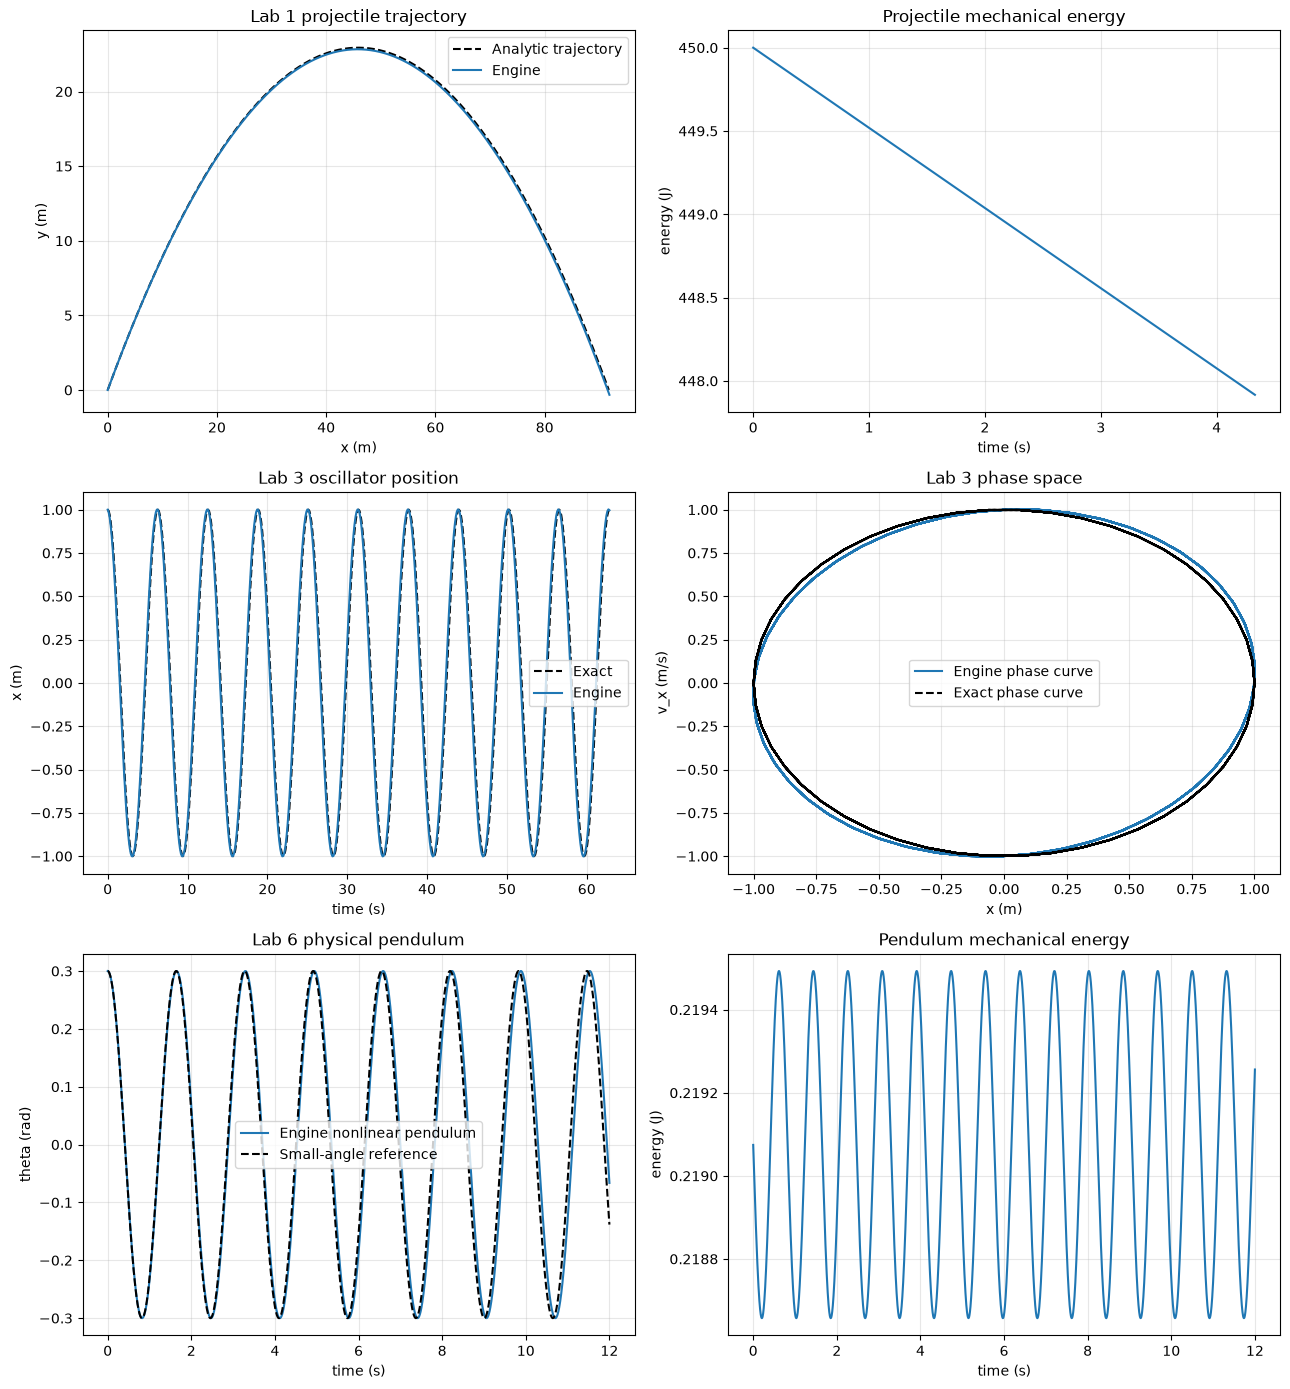

Projectile range: engine 91.853 m; analytic 91.743 m
Projectile relative energy variation: 4.630e-03
Projectile vertical momentum change: engine -42.477 kg m/s; gravity impulse -42.477 kg m/s
Oscillator period: engine 6.2790 s; analytic 6.2832 s
Oscillator relative energy variation: 1.261e-01
Pendulum relative energy variation: 3.815e-03


In [13]:
reference_time = np.linspace(0.0, projectile_flight_time, 300)
reference_x = projectile_speed * np.cos(projectile_angle) * reference_time
reference_y = (
    projectile_speed * np.sin(projectile_angle) * reference_time
    - 0.5 * g * reference_time**2
)

fig, axes = plt.subplots(3, 2, figsize=(13, 14))
axes[0, 0].plot(reference_x, reference_y, "k--", label="Analytic trajectory")
axes[0, 0].plot(projectile_positions[:, 0], projectile_positions[:, 1], label="Engine")
axes[0, 0].set(title="Lab 1 projectile trajectory", xlabel="x (m)", ylabel="y (m)")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)
axes[0, 1].plot(projectile_times, projectile_energy)
axes[0, 1].set(title="Projectile mechanical energy", xlabel="time (s)", ylabel="energy (J)")
axes[0, 1].grid(alpha=0.3)

axes[1, 0].plot(oscillator_times, oscillator_exact_x, "k--", label="Exact")
axes[1, 0].plot(oscillator_times, oscillator_x, label="Engine")
axes[1, 0].set(title="Lab 3 oscillator position", xlabel="time (s)", ylabel="x (m)")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)
axes[1, 1].plot(oscillator_x, oscillator_vx, label="Engine phase curve")
axes[1, 1].plot(oscillator_exact_x, oscillator_exact_v, "k--", label="Exact phase curve")
axes[1, 1].set(title="Lab 3 phase space", xlabel="x (m)", ylabel="v_x (m/s)")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

axes[2, 0].plot(pendulum_times, pendulum_angles, label="Engine nonlinear pendulum")
axes[2, 0].plot(pendulum_times, pendulum_small_angle, "k--", label="Small-angle reference")
axes[2, 0].set(title="Lab 6 physical pendulum", xlabel="time (s)", ylabel="theta (rad)")
axes[2, 0].legend()
axes[2, 0].grid(alpha=0.3)
axes[2, 1].plot(pendulum_times, pendulum_energy)
axes[2, 1].set(title="Pendulum mechanical energy", xlabel="time (s)", ylabel="energy (J)")
axes[2, 1].grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "lab07_comparisons.png", dpi=160, bbox_inches="tight")
plt.show()

print(f"Projectile range: engine {projectile_positions[-1, 0]:.3f} m; analytic {projectile_range_exact:.3f} m")
print(f"Projectile relative energy variation: {projectile_energy_variation:.3e}")
print(f"Projectile vertical momentum change: engine {projectile_momentum[-1, 1] - projectile_momentum[0, 1]:.3f} kg m/s; gravity impulse {projectile_expected_delta_py:.3f} kg m/s")
print(f"Oscillator period: engine {measured_period:.4f} s; analytic {oscillator_period:.4f} s")
print(f"Oscillator relative energy variation: {oscillator_energy_variation:.3e}")
print(f"Pendulum relative energy variation: {pendulum_energy_variation:.3e}")

### Part C — An Original Multi-Body Scene

#### Part 1: A chain of springs

Five equal masses are connected in a line by four body-to-body springs. Gravity acts on every mass, and an initial horizontal kick to the middle mass launches a disturbance through the chain. The chain is free to move, not attached to a wall, so its total vertical momentum changes by the external gravitational impulse. Spring forces are internal and appear in equal-and-opposite pairs. We track total mechanical energy and check that momentum change against gravity.

- **Scene:** five equal masses are joined by four springs and acted on by gravity.
- **Motion:** a horizontal kick to the middle mass sends a disturbance through the chain.
- **Checks:** energy is tracked and vertical momentum is compared with gravity's impulse.

In [14]:
from lab07_engine import SpringLink

chain_mass = 1.0
chain_spring_k = 12.0
chain_rest_length = 1.0
chain_dt = 0.0001
chain_duration = 2.0
chain_steps = int(chain_duration / chain_dt)
chain_world = World(EulerCromer())
chain_bodies = [
    Body(chain_mass, [float(index), 0.0], [0.0, 0.0])
    for index in range(5)
]
chain_bodies[2].v[0] = 3.0

for body in chain_bodies:
    chain_world.add_body(body)
chain_world.add_force(Gravity(g))
for body_a, body_b in zip(chain_bodies, chain_bodies[1:]):
    chain_world.add_force(
        SpringLink(body_a, body_b, chain_spring_k, chain_rest_length)
    )

chain_world.run(chain_steps, chain_dt)
chain_times = np.array([state.time for state in chain_world.history])
chain_positions = np.array([state.positions for state in chain_world.history])
chain_energy = np.array([state.total_energy for state in chain_world.history])
chain_momentum = np.array([state.momentum for state in chain_world.history])
chain_energy_variation = np.ptp(chain_energy) / chain_energy[0]
chain_expected_delta_py = -len(chain_bodies) * chain_mass * g * chain_times[-1]
chain_measured_delta_py = chain_momentum[-1, 1] - chain_momentum[0, 1]
assert len(chain_world.forces) == 5
assert len(chain_world.history) == chain_steps + 1
assert chain_energy_variation < 0.02
assert abs(chain_measured_delta_py - chain_expected_delta_py) < 1e-8

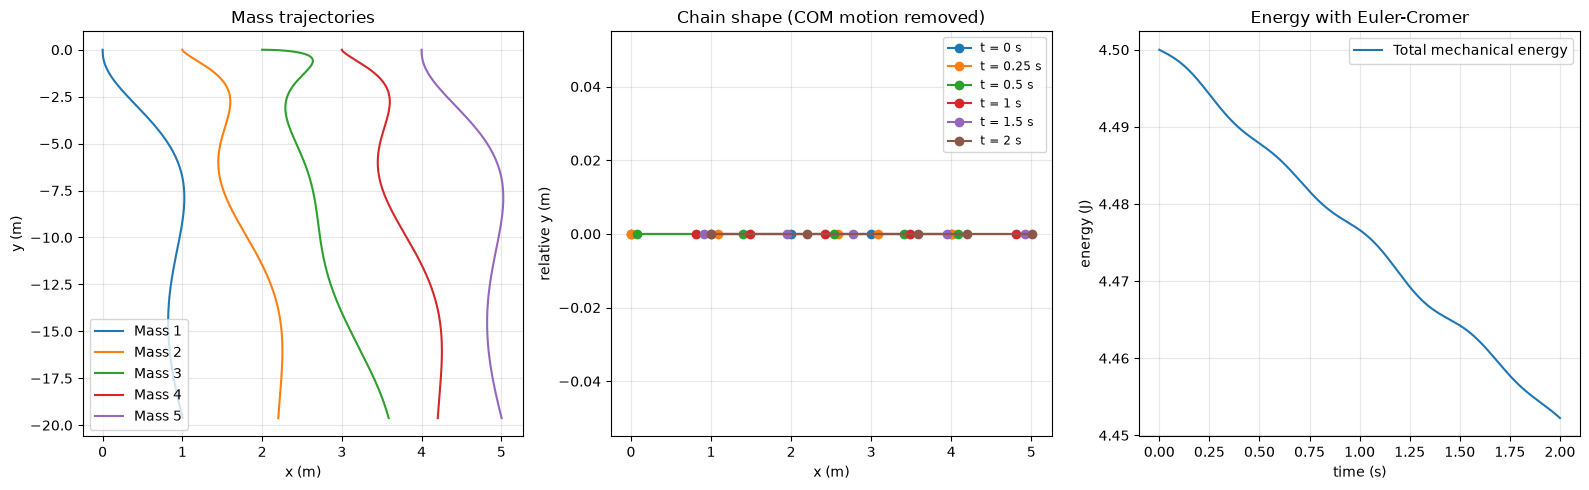

Bodies: 5; springs: 4; forces: gravity + spring links
Energy relative range over 2.0 s: 1.061%
Vertical momentum change: -98.100 kg m/s
Gravity impulse: -98.100 kg m/s


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for body_index in range(len(chain_bodies)):
    axes[0].plot(
        chain_positions[:, body_index, 0],
        chain_positions[:, body_index, 1],
        label=f"Mass {body_index + 1}",
    )
axes[0].set(title="Mass trajectories", xlabel="x (m)", ylabel="y (m)")
axes[0].legend()
axes[0].grid(alpha=0.3)

center_of_mass_y = np.mean(chain_positions[:, :, 1], axis=1)
for snapshot_time in (0.0, 0.25, 0.5, 1.0, 1.5, 2.0):
    snapshot_index = int(round(snapshot_time / chain_dt))
    relative_y = chain_positions[snapshot_index, :, 1] - center_of_mass_y[snapshot_index]
    axes[1].plot(
        chain_positions[snapshot_index, :, 0],
        relative_y,
        "o-",
        label=f"t = {snapshot_time:g} s",
    )
axes[1].set(title="Chain shape (COM motion removed)", xlabel="x (m)", ylabel="relative y (m)")
axes[1].legend(fontsize="small")
axes[1].grid(alpha=0.3)

axes[2].plot(chain_times, chain_energy, label="Total mechanical energy")
axes[2].set(title="Energy with Euler-Cromer", xlabel="time (s)", ylabel="energy (J)")
axes[2].grid(alpha=0.3)
axes[2].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "lab07_spring_chain.png", dpi=160, bbox_inches="tight")
plt.show()

print(f"Bodies: {len(chain_bodies)}; springs: {len(chain_bodies) - 1}; forces: gravity + spring links")
print(f"Energy relative range over {chain_duration:.1f} s: {chain_energy_variation:.3%}")
print(f"Vertical momentum change: {chain_measured_delta_py:.3f} kg m/s")
print(f"Gravity impulse: {chain_expected_delta_py:.3f} kg m/s")

### Bonus: Animate the spring chain

This animation uses the Part C simulation history and follows the chain's center of mass, making the spring motion visible without the whole chain falling out of frame. It saves `spring_chain_animation.gif` in the Lab 7 folder.

- **Animation:** recorded spring-chain positions are rendered as a GIF.
- **View:** the frame follows the chain's center of mass as the system falls.
- **Output:** `spring_chain_animation.gif` is saved in the Lab 7 folder.

In [16]:
from matplotlib.animation import FuncAnimation, PillowWriter

chain_com = np.mean(chain_positions, axis=1)
chain_relative_positions = chain_positions - chain_com[:, np.newaxis, :]
frame_indices = np.linspace(0, len(chain_times) - 1, 180, dtype=int)
figure, axis = plt.subplots(figsize=(8, 5))
spring_lines = [
    axis.plot([], [], "-", color="tab:blue", linewidth=2)[0]
    for _ in range(len(chain_bodies) - 1)
]
mass_points = axis.scatter([], [], s=110, color="tab:orange", edgecolor="black", zorder=3)
time_label = axis.text(0.02, 0.95, "", transform=axis.transAxes, va="top")
x_min = float(np.min(chain_relative_positions[:, :, 0]))
x_max = float(np.max(chain_relative_positions[:, :, 0]))
y_min = float(np.min(chain_relative_positions[:, :, 1]))
y_max = float(np.max(chain_relative_positions[:, :, 1]))
padding = 0.2
axis.set_xlim(x_min - padding, x_max + padding)
axis.set_ylim(y_min - padding, y_max + padding)
axis.set_aspect("equal", adjustable="box")
axis.set(xlabel="x relative to center of mass (m)", ylabel="y relative to center of mass (m)")
axis.set_title("Five-mass spring chain")
axis.grid(alpha=0.3)

def update_chain_animation(frame_number):
    frame = frame_indices[frame_number]
    points = chain_relative_positions[frame]
    for spring_index, line in enumerate(spring_lines):
        line.set_data(
            [points[spring_index, 0], points[spring_index + 1, 0]],
            [points[spring_index, 1], points[spring_index + 1, 1]],
        )
    mass_points.set_offsets(points)
    time_label.set_text(f"t = {chain_times[frame]:.2f} s")
    return (*spring_lines, mass_points, time_label)

chain_animation = FuncAnimation(
    figure,
    update_chain_animation,
    frames=len(frame_indices),
    interval=50,
    blit=True,
)
animation_path = ENGINE_DIR / "spring_chain_animation.gif"
chain_animation.save(animation_path, writer=PillowWriter(fps=20))
plt.close(figure)
print(f"Saved {len(frame_indices)} frames to {animation_path}")

Saved 180 frames to C:\Users\zakid\OneDrive\EDU\python\phys311\labs\lab07\spring_chain_animation.gif
